In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from pathlib import Path
from sklearn.metrics import classification_report, confusion_matrix

# Project paths
PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_PATH = PROJECT_ROOT / "models" / "baseline_cnn_v2_best.keras"

IMG_SIZE = (224, 224)
BATCH_SIZE = 16

CLASS_NAMES = ["Black rot", "Esca", "Healthy", "Leaf blight"]

print("Project root:", PROJECT_ROOT)
print("Model exists:", MODEL_PATH.exists())

Project root: c:\intern project 2\TerraSpectra-
Model exists: True


In [2]:
# Load saved test split
test_df = pd.read_csv(
    DATA_DIR / "splits" / "test.csv"
)

print("Test dataset shape:", test_df.shape)
print("\nClass distribution:")
print(test_df["label"].value_counts())

print("\nColumns:")
print(test_df.columns.tolist())

Test dataset shape: (462, 9)

Class distribution:
label
healthy        147
esca           129
Black rot      103
leaf blight     83
Name: count, dtype: int64

Columns:
['image_path', 'filename', 'label', 'vineyard_id', 'latitude', 'longitude', 'timestamp', 'lighting', 'weather']


In [3]:
# Load the saved best CNN v2 model
model = tf.keras.models.load_model(MODEL_PATH)

print("Model loaded successfully!")
print("Model name:", model.name)

# Resolve image paths
IMAGE_ROOT = DATA_DIR / "GVLiD_224"

folder_mapping = {
    "black rot": "Black rot",
    "esca": "esca",
    "healthy": "healthy",
    "leaf blight": "leaf blight"
}

def build_image_path(row):
    folder = folder_mapping[row["label"].strip().lower()]
    return IMAGE_ROOT / folder / row["filename"]

test_df["resolved_path"] = test_df.apply(build_image_path, axis=1)

print("\nMissing images:", 
      (~test_df["resolved_path"].apply(lambda p: p.exists())).sum())

Model loaded successfully!
Model name: sequential_1

Missing images: 0


In [4]:
# Prepare test images
def load_test_image(image_path):
    image = tf.io.read_file(str(image_path))
    image = tf.io.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, (224, 224))
    image = tf.cast(image, tf.float32) / 255.0
    return image

X_test = np.array([
    load_test_image(path).numpy()
    for path in test_df["resolved_path"]
])

# Encode actual labels
label_map = {
    "black rot": 0,
    "esca": 1,
    "healthy": 2,
    "leaf blight": 3
}

y_true = (
    test_df["label"]
    .str.strip()
    .str.lower()
    .map(label_map)
    .values
)

# Generate predictions
y_prob = model.predict(X_test, batch_size=16)
y_pred = np.argmax(y_prob, axis=1)

print("Test images:", len(X_test))
print("Predictions:", len(y_pred))
print("Prediction shape:", y_prob.shape)

29/29 ━━━━━━━━━━━━━━━━━━━━ 4s 126ms/step
Test images: 462
Predictions: 462
Prediction shape: (462, 4)


In [5]:
# Create prediction results DataFrame
results_df = test_df.copy()

results_df["actual_label"] = [
    CLASS_NAMES[i] for i in y_true
]

results_df["predicted_label"] = [
    CLASS_NAMES[i] for i in y_pred
]

results_df["confidence"] = np.max(y_prob, axis=1)

# Filter incorrectly classified images
misclassified_df = results_df[
    results_df["actual_label"] != results_df["predicted_label"]
].copy()

print("Total test images:", len(results_df))
print("Correct predictions:", len(results_df) - len(misclassified_df))
print("Incorrect predictions:", len(misclassified_df))

print("\nMisclassification rate:",
      f"{len(misclassified_df) / len(results_df) * 100:.2f}%")

display(
    misclassified_df[
        ["filename", "actual_label", "predicted_label",
         "confidence", "vineyard_id"]
    ].head(15)
)

Total test images: 462
Correct predictions: 402
Incorrect predictions: 60

Misclassification rate: 12.99%


,filename,actual_label,predicted_label,confidence,vineyard_id
101,black rot796.jpg,Black rot,Esca,0.630801,Vineyard_17
109,esca050.jpg,Esca,Leaf blight,0.638596,Vineyard_7
110,esca052.jpg,Esca,Leaf blight,0.624672,Vineyard_3
112,esca061.jpg,Esca,Leaf blight,0.570174,Vineyard_17
115,esca073.jpg,Esca,Leaf blight,0.610461,Vineyard_17
117,esca090.jpg,Esca,Leaf blight,0.575770,Vineyard_3
125,esca153.jpg,Esca,Leaf blight,0.558114,Vineyard_7
126,esca157.jpg,Esca,Leaf blight,0.515294,Vineyard_1
128,esca170.jpg,Esca,Leaf blight,0.571878,Vineyard_1
138,esca245.jpg,Esca,Leaf blight,0.534216,Vineyard_3


In [6]:
# Misclassification breakdown
print("MISCLASSIFICATION BY CLASS")
print("=" * 50)

error_summary = pd.crosstab(
    misclassified_df["actual_label"],
    misclassified_df["predicted_label"]
)

display(error_summary)

print("\nERRORS BY ACTUAL CLASS")
display(
    misclassified_df["actual_label"].value_counts()
)

print("\nERRORS BY VINEYARD")
display(
    misclassified_df["vineyard_id"].value_counts()
)

MISCLASSIFICATION BY CLASS


predicted_label,Black rot,Esca,Leaf blight
actual_label,,,
Black rot,0,1,0
Esca,0,0,27
Leaf blight,4,28,0



ERRORS BY ACTUAL CLASS


actual_label
Leaf blight    32
Esca           27
Black rot       1
Name: count, dtype: int64


ERRORS BY VINEYARD


vineyard_id
Vineyard_1     18
Vineyard_17    16
Vineyard_3     15
Vineyard_7     11
Name: count, dtype: int64

In [7]:
# Evaluate the model using the exact images used for predictions

eval_loss, eval_accuracy = model.evaluate(
    X_test,
    y_true,
    batch_size=16,
    verbose=1
)

print("\nConsistency Check")
print("-" * 35)
print(f"Model evaluation accuracy: {eval_accuracy:.4%}")
print(f"Prediction accuracy:       {np.mean(y_true == y_pred):.4%}")
print(f"Evaluation loss:           {eval_loss:.4f}")

29/29 ━━━━━━━━━━━━━━━━━━━━ 3s 94ms/step - accuracy: 0.8701 - loss: 0.2548

Consistency Check
-----------------------------------
Model evaluation accuracy: 87.0130%
Prediction accuracy:       87.0130%
Evaluation loss:           0.2548


In [8]:
print("Model input shape:", model.input_shape)
print("Model output shape:", model.output_shape)

print("\nModel architecture:")
model.summary()

Model input shape: (None, 224, 224, 3)
Model output shape: (None, 4)

Model architecture:


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,269,326 (4.84 MB)

 Trainable params: 422,788 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

 Optimizer params: 845,578 (3.23 MB)

In [9]:
print("X_test shape:", X_test.shape)
print("Pixel minimum:", X_test.min())
print("Pixel maximum:", X_test.max())
print("Pixel mean:", X_test.mean())

X_test shape: (462, 224, 224, 3)
Pixel minimum: 0.0
Pixel maximum: 1.0
Pixel mean: 0.41920313


In [10]:
# Recreate original Day 4 test dataset

def original_load_image(image_path):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, (224, 224))
    image = image / 255.0
    return image

def original_create_dataset(dataframe, batch_size=32):
    image_paths = dataframe["image_path"].values

    labels = dataframe["label"].map({
        "Black rot": 0,
        "esca": 1,
        "healthy": 2,
        "leaf blight": 3
    }).values

    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, labels)
    )

    dataset = dataset.map(
        lambda path, label: (
            original_load_image(path),
            label
        ),
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset

original_test_ds = original_create_dataset(test_df)

original_loss, original_accuracy = model.evaluate(original_test_ds)

print(f"Original pipeline accuracy: {original_accuracy:.4%}")
print(f"Original pipeline loss: {original_loss:.4f}")

15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 220ms/step - accuracy: 0.8701 - loss: 0.2548
Original pipeline accuracy: 87.0130%
Original pipeline loss: 0.2548


In [11]:
# Compare CSV paths against our reconstructed paths

print("Original CSV paths:")
display(test_df[["filename", "image_path"]].head())

print("\nReconstructed paths:")
display(test_df[["filename", "resolved_path"]].head())

print("\nPath comparison:")
for i in range(5):
    print(
        test_df.iloc[i]["filename"],
        "->",
        Path(test_df.iloc[i]["image_path"]).name ==
        test_df.iloc[i]["resolved_path"].name
    )

Original CSV paths:


,filename,image_path
0,black rot015.jpg,../data/processed/GVLiD_224\Black rot\black ro...
1,black rot026.jpg,../data/processed/GVLiD_224\Black rot\black ro...
2,black rot038.jpg,../data/processed/GVLiD_224\Black rot\black ro...
3,black rot046.jpg,../data/processed/GVLiD_224\Black rot\black ro...
4,black rot051.jpg,../data/processed/GVLiD_224\Black rot\black ro...



Reconstructed paths:


,filename,resolved_path
0,black rot015.jpg,c:\intern project 2\TerraSpectra-\data\process...
1,black rot026.jpg,c:\intern project 2\TerraSpectra-\data\process...
2,black rot038.jpg,c:\intern project 2\TerraSpectra-\data\process...
3,black rot046.jpg,c:\intern project 2\TerraSpectra-\data\process...
4,black rot051.jpg,c:\intern project 2\TerraSpectra-\data\process...



Path comparison:
black rot015.jpg -> True
black rot026.jpg -> True
black rot038.jpg -> True
black rot046.jpg -> True
black rot051.jpg -> True


In [12]:
# Load validation dataset
val_df = pd.read_csv(DATA_DIR / "splits" / "validation.csv")

val_df["resolved_path"] = val_df.apply(
    build_image_path, axis=1
)

y_val = (
    val_df["label"]
    .str.strip()
    .str.lower()
    .map(label_map)
    .values.astype(np.int32)
)

# Create validation pipeline
def preprocess_val(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

val_ds = (
    tf.data.Dataset.from_tensor_slices(
        (val_df["resolved_path"].astype(str).values, y_val)
    )
    .map(preprocess_val, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(32)
    .prefetch(tf.data.AUTOTUNE)
)

# Evaluate
val_loss, val_accuracy = model.evaluate(val_ds)

val_prob = model.predict(val_ds)
val_pred = np.argmax(val_prob, axis=1)

print(f"\nValidation Accuracy: {val_accuracy:.2%}")

print("\nClassification Report:")
print(classification_report(
    y_val,
    val_pred,
    target_names=CLASS_NAMES
))

16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 212ms/step - accuracy: 0.8816 - loss: 0.2873
16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 225ms/step

Validation Accuracy: 88.16%

Classification Report:
              precision    recall  f1-score   support

   Black rot       0.97      0.97      0.97       124
        Esca       0.74      0.80      0.77       113
     Healthy       1.00      0.98      0.99       147
 Leaf blight       0.77      0.74      0.75       106

    accuracy                           0.88       490
   macro avg       0.87      0.87      0.87       490
weighted avg       0.88      0.88      0.88       490



In [13]:
# Create validation prediction results
val_results = val_df.copy()

val_results["actual_label"] = [
    CLASS_NAMES[i] for i in y_val
]

val_results["predicted_label"] = [
    CLASS_NAMES[i] for i in val_pred
]

val_results["confidence"] = np.max(val_prob, axis=1)

# Extract incorrect predictions
val_errors = val_results[
    val_results["actual_label"] !=
    val_results["predicted_label"]
].copy()

print("Validation images:", len(val_results))
print("Correct predictions:",
      len(val_results) - len(val_errors))
print("Incorrect predictions:", len(val_errors))

print("\nMisclassification breakdown:")

display(pd.crosstab(
    val_errors["actual_label"],
    val_errors["predicted_label"]
))

Validation images: 490
Correct predictions: 432
Incorrect predictions: 58

Misclassification breakdown:


predicted_label,Black rot,Esca,Leaf blight
actual_label,,,
Black rot,0,4,0
Esca,1,0,22
Healthy,0,2,1
Leaf blight,3,25,0


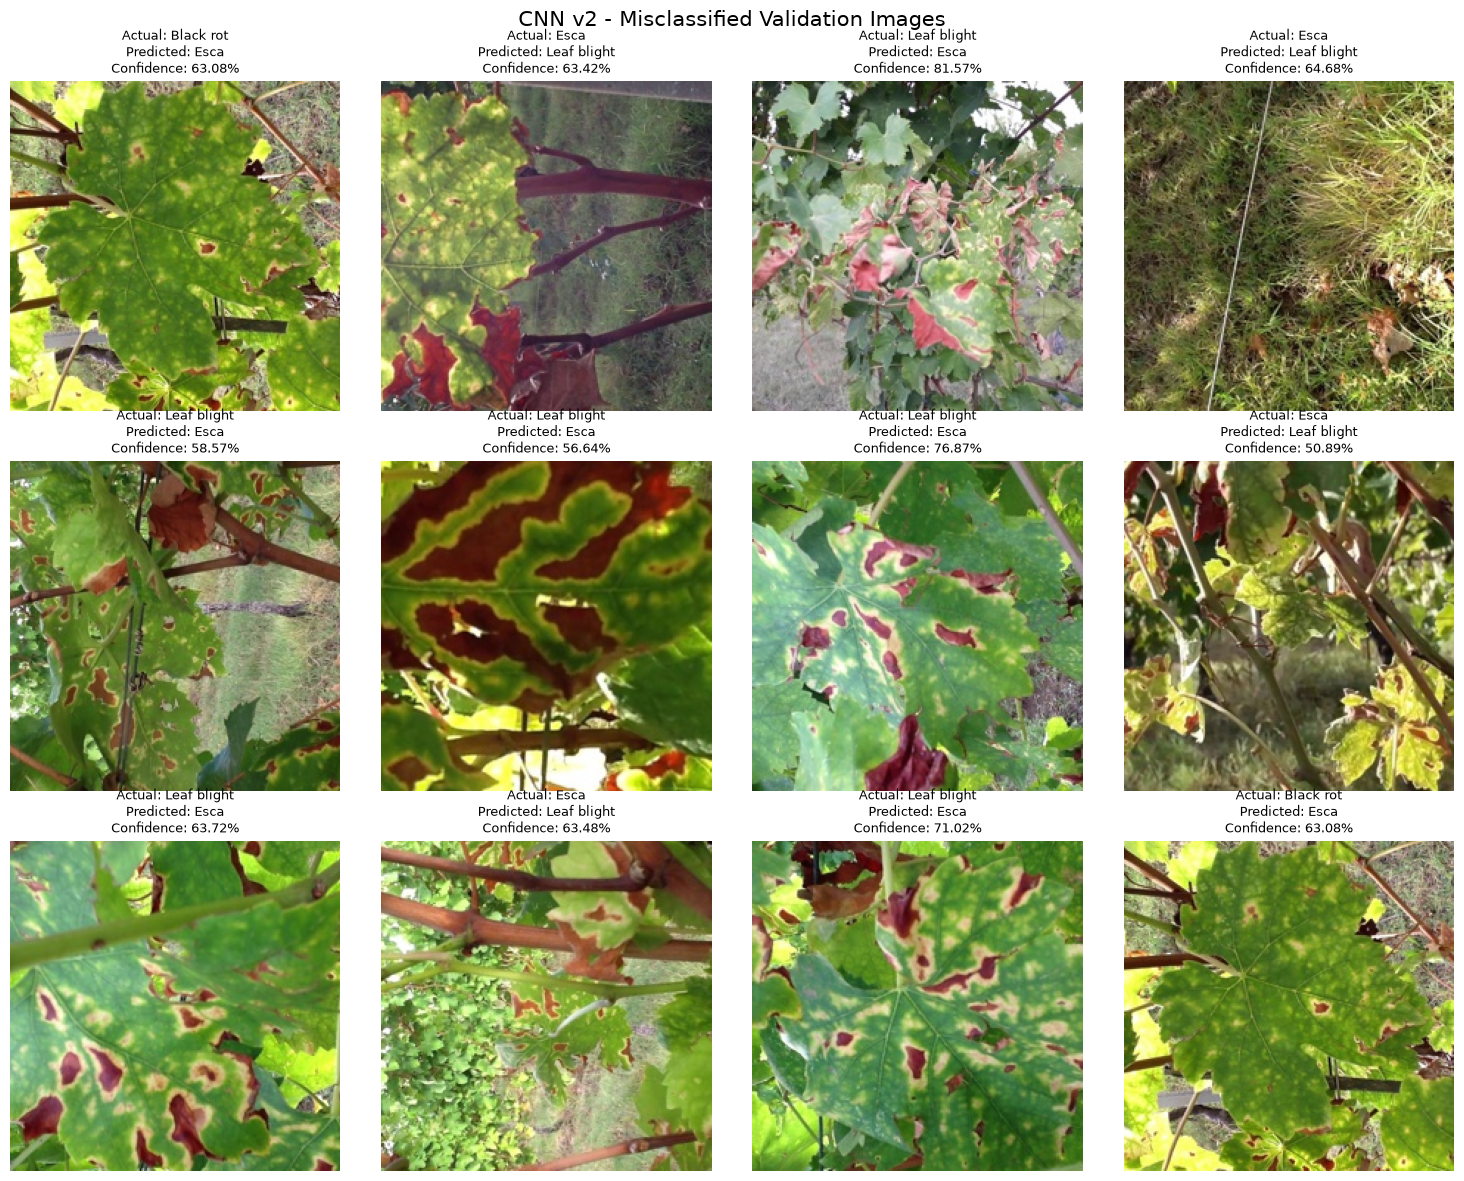

In [14]:
# Display misclassified validation images

sample_errors = val_errors.sample(
    min(12, len(val_errors)),
    random_state=42
)

plt.figure(figsize=(15, 12))

for i, (_, row) in enumerate(sample_errors.iterrows()):
    image = plt.imread(row["resolved_path"])

    plt.subplot(3, 4, i + 1)
    plt.imshow(image)
    plt.title(
        f"Actual: {row['actual_label']}\n"
        f"Predicted: {row['predicted_label']}\n"
        f"Confidence: {row['confidence']:.2%}",
        fontsize=9
    )
    plt.axis("off")

plt.suptitle(
    "CNN v2 - Misclassified Validation Images",
    fontsize=15
)
plt.tight_layout()
plt.show()

In [15]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical"),
    tf.keras.layers.RandomRotation(0.08),
    tf.keras.layers.RandomZoom(0.10),
    tf.keras.layers.RandomContrast(0.10)
], name="data_augmentation")

print("Data augmentation pipeline created!")

data_augmentation.summary()

Data augmentation pipeline created!


Model: "data_augmentation"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ ?                      │   0 (unbuilt) │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast                 │ ?                      │   0 (unbuilt) │
│ (RandomContrast)                │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [17]:
# Load training split
train_df = pd.read_csv(
    DATA_DIR / "splits" / "train.csv"
)

# Reconstruct image paths
train_df["resolved_path"] = train_df.apply(
    build_image_path, axis=1
)

print("Training dataset shape:", train_df.shape)
print("\nClass distribution:")
print(train_df["label"].value_counts())

print("\nMissing images:",
      (~train_df["resolved_path"].apply(lambda p: p.exists())).sum())

Training dataset shape: (2525, 10)

Class distribution:
label
healthy        815
esca           646
Black rot      581
leaf blight    483
Name: count, dtype: int64

Missing images: 0


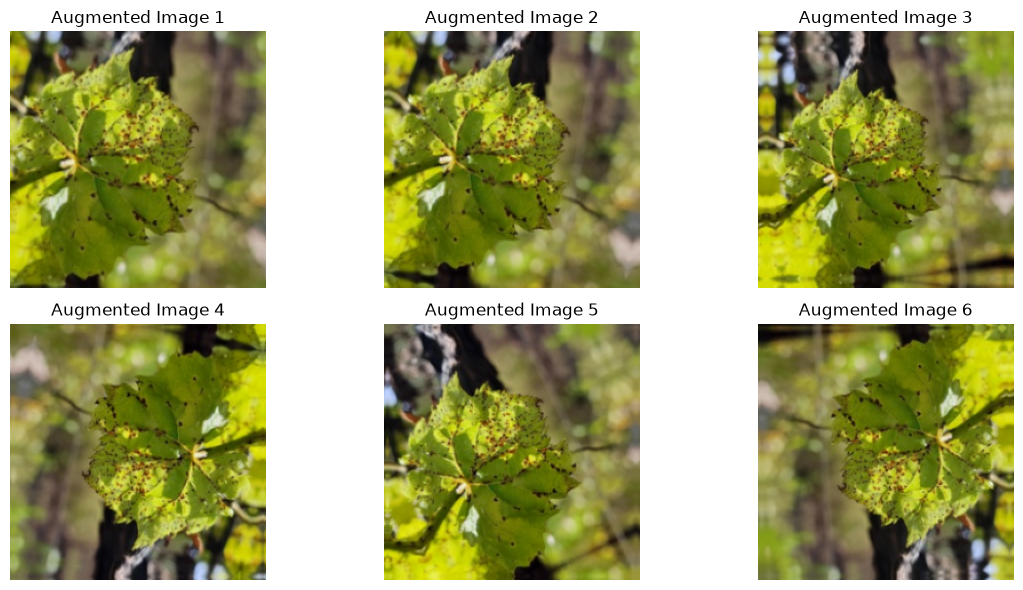

In [18]:
sample_path = train_df.iloc[0]["resolved_path"]

image = tf.io.read_file(str(sample_path))
image = tf.io.decode_jpeg(image, channels=3)
image = tf.image.resize(image, IMG_SIZE)
image = tf.cast(image, tf.float32) / 255.0

plt.figure(figsize=(12, 6))

for i in range(6):
    augmented = data_augmentation(
        tf.expand_dims(image, axis=0),
        training=True
    )

    plt.subplot(2, 3, i + 1)
    plt.imshow(tf.clip_by_value(augmented[0], 0, 1))
    plt.title(f"Augmented Image {i+1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [20]:
AUTOTUNE = tf.data.AUTOTUNE
BATCH_SIZE = 16

y_train = (
    train_df["label"]
    .str.strip()
    .str.lower()
    .map(label_map)
    .values.astype(np.int32)
)

X_train_paths = train_df["resolved_path"].astype(str).values


def load_augmented_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0

    # Add batch dimension for augmentation
    image = tf.expand_dims(image, axis=0)

    image = data_augmentation(image, training=True)

    # Remove temporary batch dimension
    image = tf.squeeze(image, axis=0)

    return image, label


train_aug_ds = (
    tf.data.Dataset.from_tensor_slices(
        (X_train_paths, y_train)
    )
    .shuffle(len(X_train_paths), seed=42)
    .map(load_augmented_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

print("Augmented training dataset ready!")
print(
    "Training batches:",
    tf.data.experimental.cardinality(train_aug_ds).numpy()
)

Augmented training dataset ready!
Training batches: 158


In [21]:
from tensorflow import keras
from tensorflow.keras import layers

aug_inputs = keras.Input(shape=(224, 224, 3))

x = layers.Conv2D(32, (3, 3), padding="same", activation="relu")(aug_inputs)
x = layers.BatchNormalization()(x)
x = layers.MaxPooling2D()(x)

x = layers.Conv2D(64, (3, 3), padding="same", activation="relu")(x)
x = layers.BatchNormalization()(x)
x = layers.MaxPooling2D()(x)

x = layers.Conv2D(128, (3, 3), padding="same", activation="relu")(x)
x = layers.BatchNormalization()(x)
x = layers.MaxPooling2D()(x)

x = layers.Conv2D(256, (3, 3), padding="same", activation="relu")(x)
x = layers.BatchNormalization()(x)
x = layers.MaxPooling2D()(x)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.4)(x)

aug_outputs = layers.Dense(4, activation="softmax")(x)

aug_model = keras.Model(
    aug_inputs,
    aug_outputs,
    name="TerraSpectra_CNN_Augmented"
)

aug_model.summary()

Model: "TerraSpectra_CNN_Augmented"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 423,748 (1.62 MB)

 Trainable params: 422,788 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

In [22]:
# Compile Experiment 3
aug_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Create callbacks
callbacks_aug = [
    keras.callbacks.ModelCheckpoint(
        filepath=str(
            PROJECT_ROOT / "models" / "augmented_cnn_best.keras"
        ),
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    ),

    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

print("Augmented CNN compiled successfully!")
print("Learning rate: 0.0001")
print("Callbacks configured successfully!")

Augmented CNN compiled successfully!
Learning rate: 0.0001
Callbacks configured successfully!


In [23]:
history_aug = aug_model.fit(
    train_aug_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=callbacks_aug
)

Epoch 1/20


c:\Users\shewa\anaconda3\envs\terraspectra\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


158/158 ━━━━━━━━━━━━━━━━━━━━ 0s 603ms/step - accuracy: 0.7073 - loss: 0.7142
Epoch 1: val_accuracy improved from None to 0.25306, saving model to c:\intern project 2\TerraSpectra-\models\augmented_cnn_best.keras

Epoch 1: finished saving model to c:\intern project 2\TerraSpectra-\models\augmented_cnn_best.keras
158/158 ━━━━━━━━━━━━━━━━━━━━ 101s 624ms/step - accuracy: 0.7073 - loss: 0.7142 - val_accuracy: 0.2531 - val_loss: 2.4753 - learning_rate: 1.0000e-04
Epoch 2/20
158/158 ━━━━━━━━━━━━━━━━━━━━ 0s 633ms/step - accuracy: 0.7572 - loss: 0.5577
Epoch 2: val_accuracy did not improve from 0.25306
158/158 ━━━━━━━━━━━━━━━━━━━━ 103s 652ms/step - accuracy: 0.7572 - loss: 0.5577 - val_accuracy: 0.2531 - val_loss: 3.5445 - learning_rate: 1.0000e-04
Epoch 3/20
158/158 ━━━━━━━━━━━━━━━━━━━━ 0s 620ms/step - accuracy: 0.7719 - loss: 0.4973
Epoch 3: val_accuracy improved from 0.25306 to 0.45918, saving model to c:\intern project 2\TerraSpectra-\models\augmented_cnn_best.keras

Epoch 3: finished savin

In [24]:
best_epoch = np.argmax(
    history_aug.history["val_accuracy"]
) + 1

best_val_acc = max(
    history_aug.history["val_accuracy"]
)

best_val_loss = min(
    history_aug.history["val_loss"]
)

print("Experiment 3 - Best Results")
print("-" * 40)
print("Best Epoch:", best_epoch)
print(f"Best Validation Accuracy: {best_val_acc:.4%}")
print(f"Best Validation Loss: {best_val_loss:.4f}")
print(f"Final Training Accuracy: {history_aug.history['accuracy'][-1]:.4%}")

Experiment 3 - Best Results
----------------------------------------
Best Epoch: 11
Best Validation Accuracy: 83.8776%
Best Validation Loss: 0.3650
Final Training Accuracy: 84.6733%


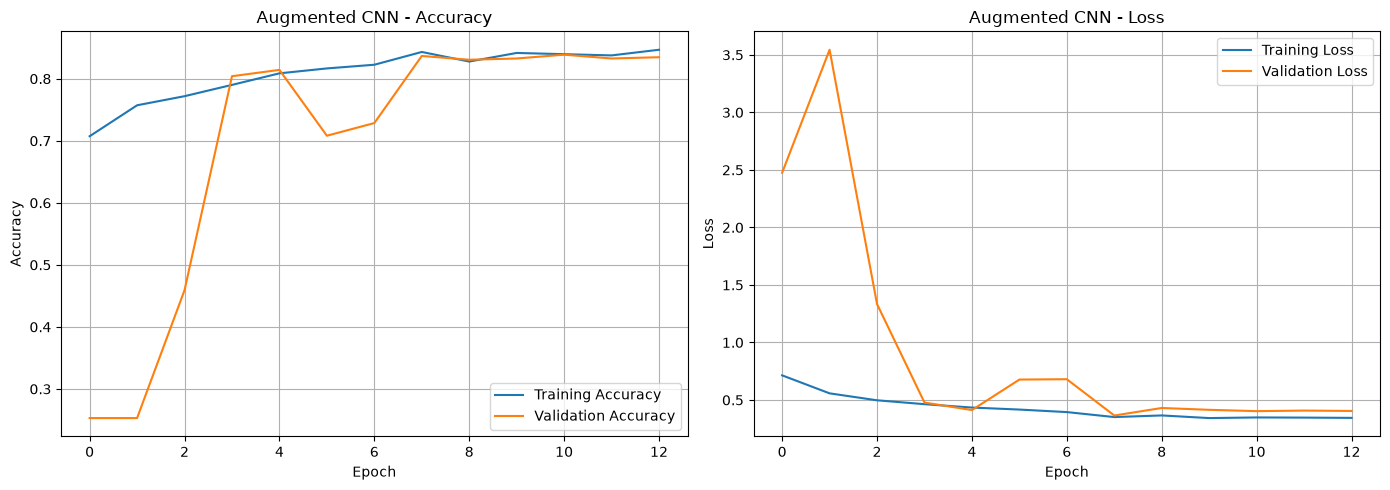

In [25]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history_aug.history["accuracy"], label="Training Accuracy")
plt.plot(history_aug.history["val_accuracy"], label="Validation Accuracy")
plt.title("Augmented CNN - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history_aug.history["loss"], label="Training Loss")
plt.plot(history_aug.history["val_loss"], label="Validation Loss")
plt.title("Augmented CNN - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [26]:
# Load checkpoint selected by validation accuracy

AUG_MODEL_PATH = (
    PROJECT_ROOT / "models" / "augmented_cnn_best.keras"
)

aug_model_best = tf.keras.models.load_model(AUG_MODEL_PATH)

# Evaluate on validation dataset
aug_val_loss, aug_val_accuracy = aug_model_best.evaluate(
    val_ds,
    verbose=1
)

print("\nBest Augmented CNN Results")
print("-" * 40)
print(f"Validation Accuracy: {aug_val_accuracy:.4%}")
print(f"Validation Loss: {aug_val_loss:.4f}")

16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 215ms/step - accuracy: 0.8388 - loss: 0.4030

Best Augmented CNN Results
----------------------------------------
Validation Accuracy: 83.8776%
Validation Loss: 0.4030


In [27]:
# Generate augmented CNN validation predictions

val_prob_aug = aug_model_best.predict(val_ds)
val_pred_aug = np.argmax(val_prob_aug, axis=1)

print("Augmented CNN - Validation Classification Report")
print("=" * 60)

print(classification_report(
    y_val,
    val_pred_aug,
    target_names=CLASS_NAMES,
    digits=4
))

16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 216ms/step
Augmented CNN - Validation Classification Report
              precision    recall  f1-score   support

   Black rot     0.9076    0.8710    0.8889       124
        Esca     0.6849    0.8850    0.7722       113
     Healthy     1.0000    0.9388    0.9684       147
 Leaf blight     0.7471    0.6132    0.6736       106

    accuracy                         0.8388       490
   macro avg     0.8349    0.8270    0.8258       490
weighted avg     0.8492    0.8388    0.8393       490



In [28]:
moderate_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.03),
    layers.RandomZoom(0.05),
    layers.RandomContrast(0.05)
], name="moderate_augmentation")

print("Moderate augmentation created!")

Moderate augmentation created!


In [29]:
def load_moderate_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0

    image = tf.expand_dims(image, axis=0)
    image = moderate_augmentation(image, training=True)
    image = tf.squeeze(image, axis=0)

    return image, label


train_moderate_ds = (
    tf.data.Dataset.from_tensor_slices(
        (X_train_paths, y_train)
    )
    .shuffle(len(X_train_paths), seed=42)
    .map(load_moderate_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

print("Moderate augmentation dataset ready!")
print(
    "Training batches:",
    tf.data.experimental.cardinality(train_moderate_ds).numpy()
)

Moderate augmentation dataset ready!
Training batches: 158


In [30]:
def build_augmented_cnn(model_name):
    inputs = keras.Input(shape=(224, 224, 3))

    x = layers.Conv2D(32, 3, padding="same", activation="relu")(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D()(x)

    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D()(x)

    x = layers.Conv2D(128, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D()(x)

    x = layers.Conv2D(256, 3, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D()(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.4)(x)

    outputs = layers.Dense(4, activation="softmax")(x)

    return keras.Model(inputs, outputs, name=model_name)


moderate_model = build_augmented_cnn(
    "TerraSpectra_CNN_Moderate_Augmentation"
)

moderate_model.summary()

Model: "TerraSpectra_CNN_Moderate_Augmentation"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 423,748 (1.62 MB)

 Trainable params: 422,788 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

In [31]:
moderate_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks_moderate = [
    keras.callbacks.ModelCheckpoint(
        filepath=str(
            PROJECT_ROOT / "models" / "moderate_augmented_cnn_best.keras"
        ),
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

print("Moderate augmented CNN compiled successfully!")

Moderate augmented CNN compiled successfully!
